# DISCO-DJ on Arrhenius: benchmarks for reionization simulations

Issue [#48](https://github.com/cosmic-reionization/pyC2Ray/issues/48). DISCO-DJ ([List, Hahn, Flöss & Winkler 2025](https://arxiv.org/abs/2510.05206), `main` at `a687972`) on NVIDIA GH200 (96 GB HBM3, one GPU per run); L = 100 Mpc/h, Giri+24 cosmology (Ω_m = 0.32, h = 0.67, σ_8 = 0.83), z = 150 → 5, same linear P(k) as the pkdgrav3 benchmarks (#47, `pkdgrav3_benchmarks_arrhenius.ipynb`), which also serve as the accuracy reference here.

Sections follow the checklist of #48. Each item is either done (results below) or carries a note why not.

| Item | | Status |
|---|---|---|
| **Prerequisites** | env, JAX on GH200, quickstart | done; developers not yet asked about multi-GPU |
| **A1** | example notebooks; GPU vs. CPU | done |
| **A2** | single vs. double precision | done |
| **A3** | against pkdgrav3 (#47) from identical ICs | done (256³, 512³) |
| **A4** | output readable by pyC2Ray | done |
| **B1** | time and memory vs. N and PM grid | done |
| **B2** | accuracy vs. cost | done |
| **B3** | 99 outputs | per-output loop done; `collect_all` broken upstream |
| **B4** | memory saving | done; unified memory (HBM + host) up to 896³ |
| **B5** | Tree-PM | not possible at `a687972` |
| **B6** | gradients | done (reverse mode); forward mode not supported |
| **C1** | 1, 2, 4 runs per node | done |
| **C2** | multi-GPU scaling of one run | not possible (single-device code) |
| **D1/D2** | production-style run; time split, sizes | done |
| **E1–E3** | sources, conversion, pyC2Ray run | not done in this round (needs haloes) |
| **F1** | GPU-hours and storage | done (N-body part), next to pkdgrav3 |
| **F2** | combined N-body + pyC2Ray estimate | not done (needs E and #45) |

Scripts, job files and result files: `disco_dj/` (`benchmark_scripts/`, `benchmark_results/arrhenius/`). This notebook only reads the result files; rebuild it with `disco_dj/benchmark_scripts/make_notebooks.py`.

Timings: *run* = execution only (best of the repeats after the first call); *compile* = first call − run; *setup* = timetables + linear P(k) + ICs + nLPT. Peak memory from JAX's allocator (`peak_bytes_in_use`, no preallocation).

In [1]:
import json, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RES = Path("disco_dj/benchmark_results/arrhenius")
GiB = 2**30

def load(test, latest=False):
    """Records of a test from all jobs (each with its file's metadata and job id attached).
    latest=True keeps only the newest record per label (by Slurm job id)."""
    out = []
    for f in sorted(RES.glob(f"{test}/{test}_*.json"), key=lambda f: int(re.findall(r"_(\d+)\.json", f.name)[0])):
        d = json.loads(f.read_text())
        job = int(re.findall(r"_(\d+)\.json", f.name)[0])
        out += [r | {"_meta": d["metadata"], "_job": job} for r in d["records"]]
    if latest:
        out = list({r.get("label", r.get("notebook")): r for r in out}.values())
    if not out:
        print(f"no results for {test}")
    return out

def kclean(o, key, kkey="k"):
    k, v = np.asarray(o[kkey], float), np.asarray(o[key], float)
    m = np.isfinite(k) & np.isfinite(v)
    return k[m], v[m]

def at(o, key, k0):
    k, v = kclean(o, key)
    return np.interp(k0, k, v)

def peak(r):
    return r.get("mem", {}).get("peak_bytes_in_use", 0) / GiB

def f2(v, p=2):
    return f"{v:.{p}f}" if isinstance(v, (int, float)) and v == v else "-"


# Prerequisites
- **Environment on a GPU node:** done. `disco_dj/envs/arrhenius_disco_dj.sh` (conda env `discodj` built on an aarch64 GPU node by `jobs/arrhenius_setup.sh`; `jax[cuda12]` 0.7.2, Diffrax 0.7.0; `pip freeze` in `benchmark_results/arrhenius/`).
- **JAX sees all 4 GH200s; quickstart and `demo.py` on GPU:** done (`jobs/arrhenius_smoke.sh`, job 5805766: all output modes at 128³, `demo.py` OK). Arrhenius allocates and bills whole GPU nodes, so each process is pinned to one GPU (`CUDA_VISIBLE_DEVICES`) and its 72 Grace cores (`taskset`).
- **Ask the developers about multi-GPU plans and settings for z ≈ 5:** not done yet.

Software and hardware recorded with the results:

In [2]:
m = load("B1")[0]["_meta"]
print("system:", m["system"], "| GPU:", m["gpu"][0], "| CPU:", m["cpu"], m["cpu_arch"])
print("python", m["python"], "| jax", m["jax"], "| jaxlib", m["jaxlib"], "| backend", m["jax_backend"], "|", m["packages"])
print("DISCO-DJ", m["discodj"].get("commit"), "| pyC2Ray (scripts)", m["benchmark_setup"].get("commit"))

system: arrhenius | GPU: NVIDIA GH200 120GB, 97871 MiB, 580.196.07 | CPU: Neoverse-V2 aarch64
python 3.12.16 | jax 0.7.2 | jaxlib 0.7.2 | backend PJRT C API
cuda 12090 | {'diffrax': '0.7.0', 'equinox': '0.13.8', 'numpy': '2.5.5', 'einops': '0.8.2'}
DISCO-DJ a687972d | pyC2Ray (scripts) e07b6fb0


# A. Correctness

## A1. Example notebooks; GPU vs. CPU

### Upstream example notebooks
The four notebooks of the DISCO-DJ repository executed on one GH200 (`jobs/arrhenius_A_notebooks.sh`). They also need `seaborn`, which is not a DISCO-DJ dependency (the first attempt failed on the import; now part of the env setup).

In [3]:
for r in load("A_notebooks", latest=True):
    print(f"{r['notebook']:34s} {r['status']:6s} {r['time_s']:4d} s   (job {r['_job']})")

disco_dj_1d_example                ok       70 s   (job 5809824)
disco_dj_1d_derivative_example     ok       40 s   (job 5809824)
disco_dj_2d_example                ok       28 s   (job 5809824)
disco_dj_3d_example                ok       29 s   (job 5809824)


### GPU vs. CPU
Same 64³ run (seed, 20 BullFrog steps) on the GH200 and on the Grace CPU (`JAX_PLATFORMS=cpu`).

gpu64 ok delta std = 0.3898203 run 0.63 s
cpu64 ok delta std = 0.3898205 run 0.70 s
max |diff| = 6.48e-05, rel. rms diff = 7.39e-06


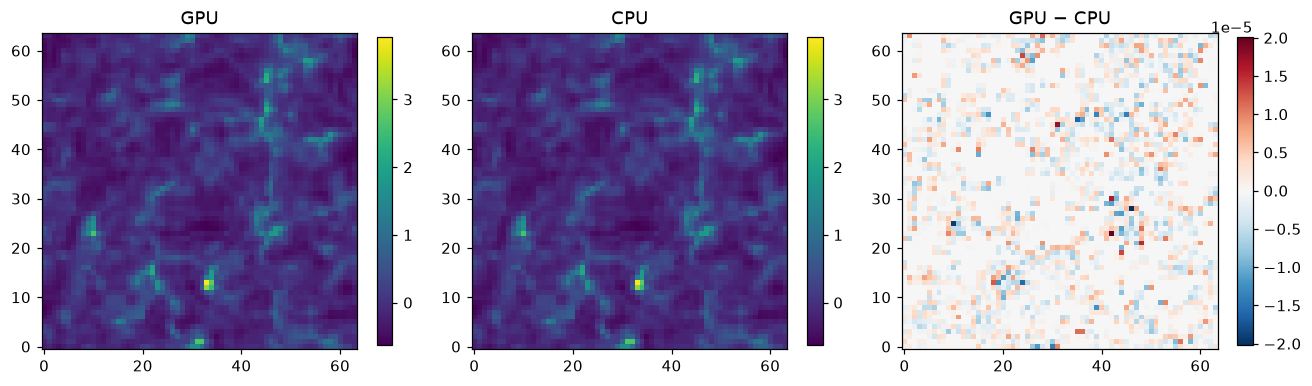

In [4]:
sm = {r["label"]: r for r in load("smoke")}
for lab in ("gpu64", "cpu64"):
    r = sm.get(lab)
    if r: print(lab, r["status"], "delta std = %.7f" % r["delta_stats"]["std"], "run %.2f s" % r["timings"]["run"])
try:
    g, c = np.load(sm["gpu64"]["saved_delta"]), np.load(sm["cpu64"]["saved_delta"])
    print("max |diff| = %.2e, rel. rms diff = %.2e" % (abs(g - c).max(), np.sqrt(((g - c)**2).mean()) / g.std()))
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
    for a, f, t in zip(ax, (g, c, g - c), ("GPU", "CPU", "GPU − CPU")):
        im = a.imshow(f[f.shape[0] // 2].T, origin="lower", cmap="RdBu_r" if "−" in t else "viridis")
        a.set_title(t); a.grid(False); plt.colorbar(im, ax=a, shrink=0.8)
    plt.tight_layout()
except (KeyError, FileNotFoundError) as e:
    print("saved fields not available here:", e)

## A2. Single vs. double precision
`jax_enable_x64` with `precision="double"`. Accuracy against pkdgrav3 (256³, same ICs) and cost vs. N (50 steps, PM 1×).

In [5]:
ap = load("A_prec", latest=True)
cmp_ = {r["label"]: r for r in ap if "outputs" in r}
print(f"{'config':44s} {'z':>3s}  max|P_d/P_s - 1| (k<k_Ny/2)  max|r_d - r_s|")
for lab, r in cmp_.items():
    if not lab.startswith("single:"): continue
    rd = cmp_.get("double:" + lab[7:])
    if rd is None: continue
    for os_, od in zip(r["outputs"], rd["outputs"]):
        k, ps = kclean(os_, "P_dj"); _, pd = kclean(od, "P_dj"); _, rs = kclean(os_, "r"); _, rdd = kclean(od, "r")
        m = k < np.pi * 256 / 100 / 2
        if os_["z"] in (10.0, 5.0):
            print(f"{lab[7:]:44s} {os_['z']:3.0f}  {abs(pd[m] / ps[m] - 1).max():.2e}                    {abs(rdd[m] - rs[m]).max():.2e}")
runs = {r["label"]: r for r in ap if "timings" in r and r.get("status") == "ok"}
print(f"\n{'N':>5s} {'run single':>10s} {'run double':>10s} {'ratio':>6s} {'mem single':>10s} {'mem double':>10s} {'ratio':>6s}")
for N in (128, 256, 384, 512, 640):
    s, d = runs.get(f"N{N}_single"), runs.get(f"N{N}_double")
    if s and d:
        print(f"{N:5d} {s['timings']['run']:10.2f} {d['timings']['run']:10.2f} {d['timings']['run'] / s['timings']['run']:6.2f} "
              f"{peak(s):10.2f} {peak(d):10.2f} {peak(d) / peak(s):6.2f}")

config                                         z  max|P_d/P_s - 1| (k<k_Ny/2)  max|r_d - r_s|
bullfrog:10                                   10  7.43e-06                    8.09e-06
bullfrog:10                                    5  1.08e-05                    6.81e-06
bullfrog:50:res_pm=512,worder=3,antialias=1   10  8.40e-06                    7.11e-06
bullfrog:50:res_pm=512,worder=3,antialias=1    5  1.44e-05                    6.83e-06
symplectic:100                                10  7.97e-06                    5.24e-06
symplectic:100                                 5  6.75e-06                    5.77e-06

    N run single run double  ratio mem single mem double  ratio
  128       0.68       0.77   1.14       0.41       0.65   1.61
  256       1.03       1.41   1.37       3.03       5.00   1.65
  384       1.96       2.93   1.50       8.44      16.88   2.00
  512       4.05       6.29   1.55      23.01      40.02   1.74
  640       6.80      11.33   1.67      39.16      72.27   1.85

## A3. Against pkdgrav3 (#47)
Same cosmology and resolution, from identical ICs; matter P(k) and r(k) at z = 10, 8, 6, 5.

pkdgrav3 (develop `92993cf5`, GPU build, one GH200) writes Zel'dovich ICs at z = 150 for the same seed and transfer function as its 2LPT reference run (90 steps z = 150 → 5, snapshots at z = 10, 8, 6, 5). The linear field $-\nabla\cdot\psi(q)$ is passed to DISCO-DJ (`with_external_ics(delta=...)`), which builds its own 2LPT. Both particle sets are CIC-gridded on the particle-grid mesh and MAK-deconvolved; compared by $P_\mathrm{DJ}/P_\mathrm{pkd}$ and $r(k)=P_\times/\sqrt{P_\mathrm{DJ}P_\mathrm{pkd}}$. Each DISCO-DJ run goes z = 150 → z_out on its own. Scripts: `compare_pkdgrav3.py`, `jobs/arrhenius_A_B2.sh`.

### IC handover check
DISCO-DJ's 1LPT displacement at z = 150 against pkdgrav3's ψ(q).

In [6]:
b2all = [r for r in load("B2")]
byN = {}
for r in b2all:
    byN.setdefault(r["ic_check"]["N"], {})[r["config"]] = r
for N, d in sorted(byN.items()):
    ic = next(iter(d.values()))["ic_check"]
    print(f"N = {N}^3: r(psi) = {ic['psi_r']:.7f}, amplitude ratio = {ic['psi_amp_ratio_pkd_over_dj']:.7f}, "
          f"lattice offset = {ic['lattice_offset_cells']:.4f} cells, rms psi = {ic['rms_psi_pkd']:.4f} Mpc/h")

N = 256^3: r(psi) = 0.9999975, amplitude ratio = 1.0000007, lattice offset = 0.5000 cells, rms psi = 0.0378 Mpc/h
N = 512^3: r(psi) = 0.9999996, amplitude ratio = 1.0000004, lattice offset = 0.5001 cells, rms psi = 0.0379 Mpc/h


### Power-spectrum ratio and cross-correlation
Representative configurations. Grey band: ±1 %. Dotted line: half the grid Nyquist frequency. At 512³ the most accurate setting (PM 2× + TSC + interlacing) does not fit in the 96 GB HBM; it was run with unified memory (B4, job 5835092).

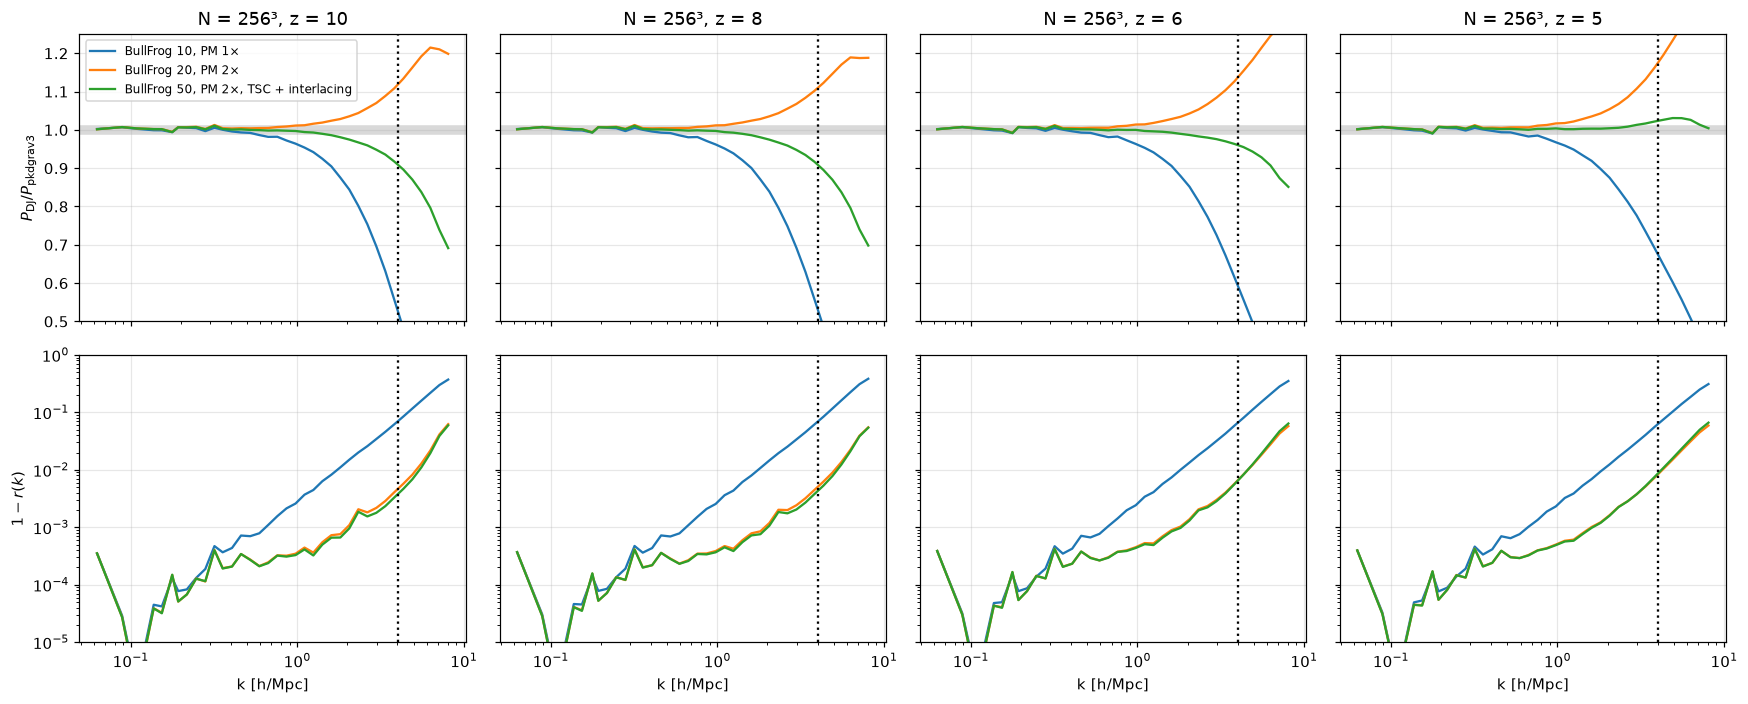

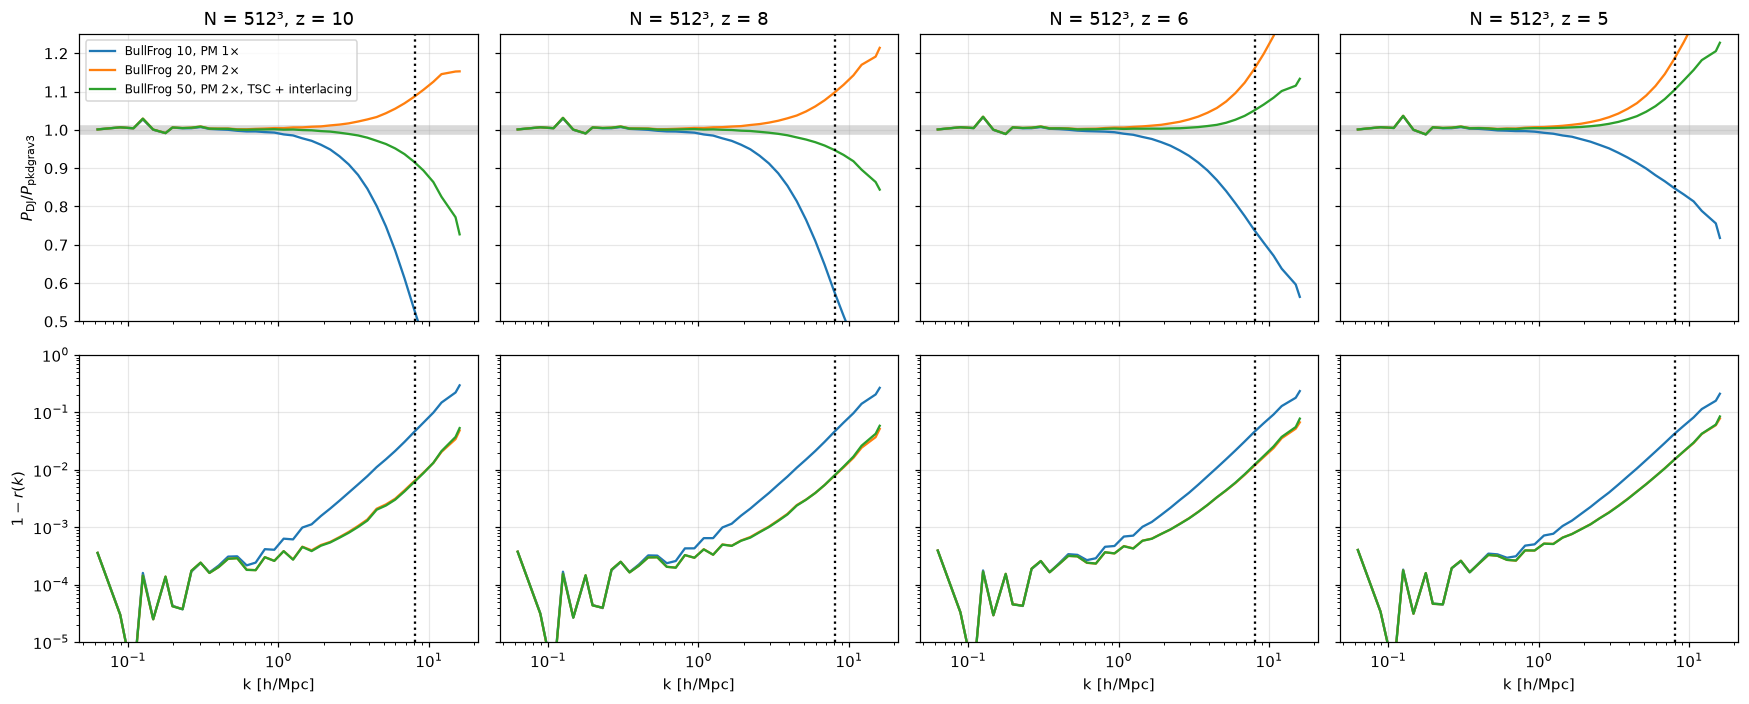

In [7]:
pick = {256: {"bullfrog:10": "BullFrog 10, PM 1×", "bullfrog:20:res_pm=512": "BullFrog 20, PM 2×",
              "bullfrog:50:res_pm=512,worder=3,antialias=1": "BullFrog 50, PM 2×, TSC + interlacing"},
        512: {"bullfrog:10": "BullFrog 10, PM 1×", "bullfrog:20:res_pm=1024": "BullFrog 20, PM 2×",
              "bullfrog:50:res_pm=1024,worder=3,antialias=1": "BullFrog 50, PM 2×, TSC + interlacing"}}
for N, cfgs in pick.items():
    d = byN.get(N, {})
    if not d: continue
    zs = [o["z"] for o in d["bullfrog:10"]["outputs"]]
    kny = np.pi * N / 100.0
    fig, ax = plt.subplots(2, len(zs), figsize=(4 * len(zs), 6.5), sharex=True, sharey="row")
    for j, z in enumerate(zs):
        for cfg, lab in cfgs.items():
            if cfg not in d or d[cfg]["status"] != "ok": continue
            o = next(o for o in d[cfg]["outputs"] if o["z"] == z)
            k, ra = kclean(o, "ratio"); _, r = kclean(o, "r")
            ax[0, j].semilogx(k, ra, label=lab); ax[1, j].semilogx(k, 1 - r, label=lab)
        ax[0, j].axhspan(0.99, 1.01, color="0.85"); ax[0, j].set_title(f"N = {N}³, z = {z:g}")
        ax[1, j].set_yscale("log"); ax[1, j].set_xlabel("k [h/Mpc]")
        for a in ax[:, j]: a.axvline(kny / 2, ls=":", c="k")
    ax[0, 0].set_ylabel(r"$P_\mathrm{DJ}/P_\mathrm{pkdgrav3}$"); ax[0, 0].set_ylim(0.5, 1.25)
    ax[1, 0].set_ylabel(r"$1 - r(k)$"); ax[1, 0].set_ylim(1e-5, 1)
    ax[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Summary tables (z = 10 and 5)
r and the power ratio at k = 1, 2, 4 h/Mpc; run time of one DISCO-DJ run z = 150 → z (incl. compilation).

In [8]:
for N, d in sorted(byN.items()):
    print(f"--- N = {N}^3 (k_Ny = {np.pi * N / 100:.1f} h/Mpc)")
    print(f"{'config':46s} {'z':>3s}  r(1)   r(2)   r(4)   P(0.5) P(1)   P(2)   P(4)   t [s]")
    for cfg, r in d.items():
        if r["status"] != "ok": print(f"{cfg:46s} {r['status']}: {r.get('error', '')[:60]}"); continue
        for o in r["outputs"]:
            if o["z"] in (10.0, 5.0):
                print(f"{cfg:46s} {o['z']:3.0f}  " + "  ".join(f"{at(o,'r',k):.3f}" for k in (1, 2, 4)) + "  "
                      + "  ".join(f"{at(o,'ratio',k):.3f}" for k in (0.5, 1, 2, 4)) + f"  {o['t_run_incl_compile']:5.2f}")

--- N = 256^3 (k_Ny = 8.0 h/Mpc)
config                                           z  r(1)   r(2)   r(4)   P(0.5) P(1)   P(2)   P(4)   t [s]
bullfrog:5                                      10  0.998  0.988  0.937  0.993  0.964  0.857  0.540   2.24
bullfrog:5                                       5  0.998  0.991  0.948  0.992  0.965  0.879  0.674   0.80
bullfrog:10                                     10  0.997  0.986  0.930  0.993  0.962  0.851  0.531   1.52
bullfrog:10                                      5  0.998  0.988  0.937  0.994  0.966  0.880  0.676   0.90
bullfrog:20                                     10  0.997  0.985  0.928  0.992  0.961  0.849  0.526   1.63
bullfrog:20                                      5  0.997  0.986  0.931  0.994  0.966  0.878  0.673   0.92
bullfrog:50                                     10  0.997  0.985  0.927  0.992  0.961  0.847  0.525   1.81
bullfrog:50                                      5  0.997  0.986  0.928  0.994  0.965  0.877  0.671   1.17
bull

Notes:
- The IC handover is exact (r(ψ) ≥ 0.999997 at both resolutions), so the differences are force resolution and time integration. At 512³ the largest displacements reach 0.85 cells, so the lattice site of each particle is taken from pkdgrav3's particle order (x fastest), not by rounding positions.
- At 512³ one sparse bin (k ≈ 0.13 h/Mpc, few modes) is 3.6 % high in every configuration, the symplectic integrator included; all other bins below k = 1 agree within 1 %.
- **512³ with PM 2× + TSC + interlacing** (unified memory, ~100 s per run) is within 1 % of pkdgrav3 to k = 2 h/Mpc at both z = 10 (0.996) and z = 5 (1.008), without the cancellation seen at 256³; at k = 4 it is −2.2 % (z = 10) and +2.9 % (z = 5).
- `evaluate_cross_power_spectrum` returns r(k) as its 2nd value (the docstring says “Pkx”). Job 5806041 divided by √(P₁P₂) once more; its stored r was corrected exactly offline (note in the result file).

## A4. Output readable by pyC2Ray
The production-style runs (B3/D) write each of the 99 density grids (1+δ, float32) in pyC2Ray's layout, `disco.<i>.den.<N>.npy` (read with `np.load`) and `disco.<i>.den.<N>.0` (pkdgrav3 raw format, read with `tools21cm.Pkdgrav3data.load_density_field`, which transposes), plus `redshift_density.txt`. `check_outputs.py` reads every file both ways and compares them, and compares the last output with the final field kept in memory.

In [9]:
print(f"{'run':34s} {'files':>5s} {'z range':>14s} {'max|d_bin-d_npy|':>16s} {'r(final,last)':>14s} {'read npy/bin [s]':>16s} status")
for r in load("A_io"):
    print(f"{Path(r['write_dir']).name:34s} {r['n_npy']:5d} {r['z_first']:6.2f}-{r['z_last']:6.3f} {r['max_abs_diff_bin_vs_npy']:16.1e} "
          f"{r['final_vs_last_output_r']:14.10f} {r['t_read_npy_per_file']:7.3f}/{r['t_read_bin_per_file']:.3f}   {r['status']}")

run                                files        z range max|d_bin-d_npy|  r(final,last) read npy/bin [s] status
N256_pm1_grid256                      99  30.00- 5.015          1.4e-05   1.0000000000   0.023/0.080   ok
N512_pm1_grid256                      99  30.00- 5.015          1.4e-05   1.0000000000   0.026/0.081   ok
N512_pm2_tsc_aa                       99  30.00- 5.015          1.4e-05   1.0000000000   0.027/0.084   ok
N768_pm1_free                         99  30.00- 5.015          2.4e-05   1.0000000000   0.027/0.083   ok
N640_pm1                              99  30.00- 5.015          2.4e-05   1.0000000000   0.092/0.113   ok
N512_pm2_tsc_aa_jit                   99  30.00- 5.015          1.4e-05   1.0000000000   0.027/0.084   ok


# B. Benchmarks

## B1. Time and peak GPU memory vs. N
50 BullFrog steps z = 150 → 5, final state only; PM grid 1× and 2× the particle grid. Crosses: out of memory.

    N  PM status  run[s] compile  setup peak[GiB]  B/part
  128  1x     ok    0.70    1.64   15.7      0.41     208
  256  1x     ok    1.06    1.67    9.8      3.03     194
  384  1x     ok    2.01    1.70   10.0      8.44     160
  512  1x     ok    4.13    1.87   10.4     23.01     184
  640  1x     ok    6.95    1.86   12.2     39.16     160
  768  1x     ok   18.05    1.76   14.9     67.50     160
  896  1x    oom       -       -      -     40.29     nan
 1024  1x    oom       -       -      -     60.12     nan
 1152  1x    oom       -       -      -     62.76     nan
 1280  1x    oom       -       -      -     62.60     nan
  128  2x     ok    0.92    1.78   16.0      0.59     303
  256  2x     ok    2.01    1.90   10.2      4.54     290
  384  2x     ok    5.40    2.65    9.5     13.52     256
  512  2x     ok   10.97    2.13   10.4     35.28     282
  640  2x    oom       -       -   12.7     29.99     nan
  768  2x    oom       -       -   14.9     60.86     nan


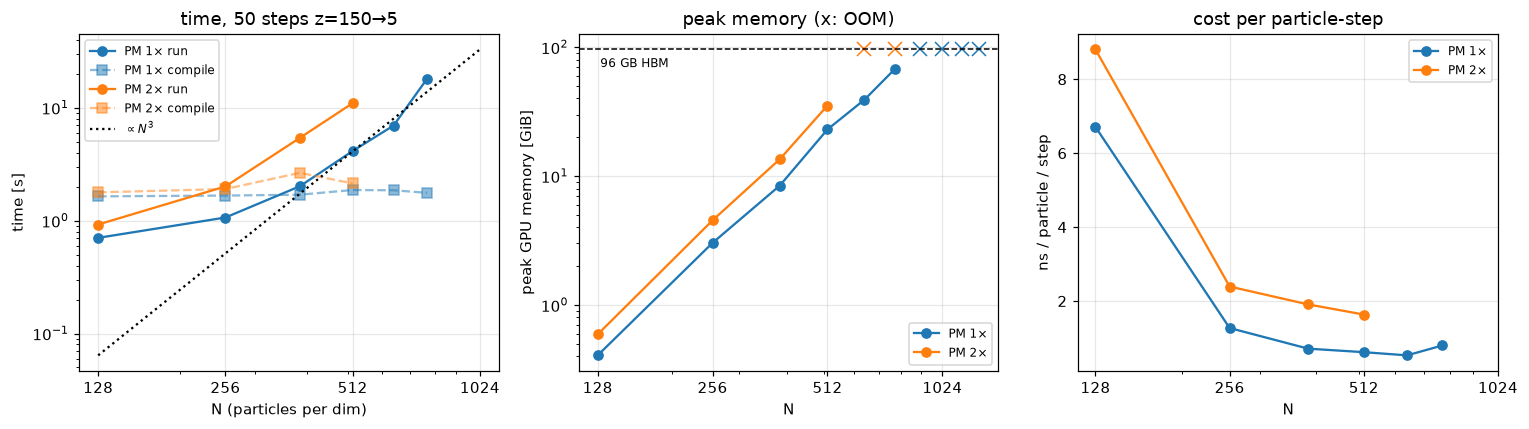

In [10]:
b1 = load("B1")
rows = []
for r in b1:
    pm = r["params"]["res_pm"] // r["params"]["res"]
    rows.append((r["params"]["res"], pm, r["status"], r["timings"].get("run"), r["timings"].get("compile"),
                 r["timings"].get("setup"), peak(r)))
rows.sort(key=lambda x: (x[1], x[0]))
print(f"{'N':>5s} {'PM':>3s} {'status':>6s} {'run[s]':>7s} {'compile':>7s} {'setup':>6s} {'peak[GiB]':>9s} {'B/part':>7s}")
for N, pm, st, t, c, s, mem in rows:
    print(f"{N:5d} {pm:2d}x {st:>6s} {f2(t):>7s} {f2(c):>7s} {f2(s,1):>6s} {mem:9.2f} "
          f"{(mem * GiB / N**3 if st == 'ok' else float('nan')):7.0f}")
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for pm, c in ((1, "C0"), (2, "C1")):
    ok = [x for x in rows if x[1] == pm and x[2] == "ok"]; bad = [x for x in rows if x[1] == pm and x[2] != "ok"]
    N = np.array([x[0] for x in ok])
    ax[0].loglog(N, [x[3] for x in ok], "o-", c=c, label=f"PM {pm}× run")
    ax[0].loglog(N, [x[4] for x in ok], "s--", c=c, alpha=0.5, label=f"PM {pm}× compile")
    ax[1].loglog(N, [x[6] for x in ok], "o-", c=c, label=f"PM {pm}×")
    ax[1].plot([x[0] for x in bad], [96] * len(bad), "x", c=c, ms=9)
    ax[2].semilogx(N, [x[3] / (x[0]**3 * 50) * 1e9 for x in ok], "o-", c=c, label=f"PM {pm}×")
Nr = np.array([128, 1024]); ax[0].loglog(Nr, (Nr / 512)**3 * 4.1, "k:", label=r"$\propto N^3$")
ax[1].axhline(96, c="k", ls="--", lw=1); ax[1].text(130, 70, "96 GB HBM", fontsize=8)
ax[0].set(xlabel="N (particles per dim)", ylabel="time [s]", title="time, 50 steps z=150→5")
ax[1].set(xlabel="N", ylabel="peak GPU memory [GiB]", title="peak memory (x: OOM)")
ax[2].set(xlabel="N", ylabel="ns / particle / step", title="cost per particle-step")
for a in ax:
    a.legend(fontsize=8); a.set_xticks([128, 256, 512, 1024], [128, 256, 512, 1024]); a.xaxis.set_minor_formatter(plt.NullFormatter())
plt.tight_layout()

Small runs are overhead-dominated (~0.7 s for 50 steps at 128³); from 512³ on the cost approaches $N^3$ (≈ 0.6 ns per particle and step). Largest runs on one GH200: **768³ with PM 1×** (67.5 GiB), **512³ with PM 2×** (35 GiB); see B4.

## B2. Accuracy vs. cost
Against pkdgrav3 from identical ICs (A3). Left/middle: power ratio at z = 5 vs. number of steps per time stepper (PM 1×, 256³). Right: accuracy vs. run time for all configurations (blue PM 1×, orange PM 2×; circles 256³, squares 512³).

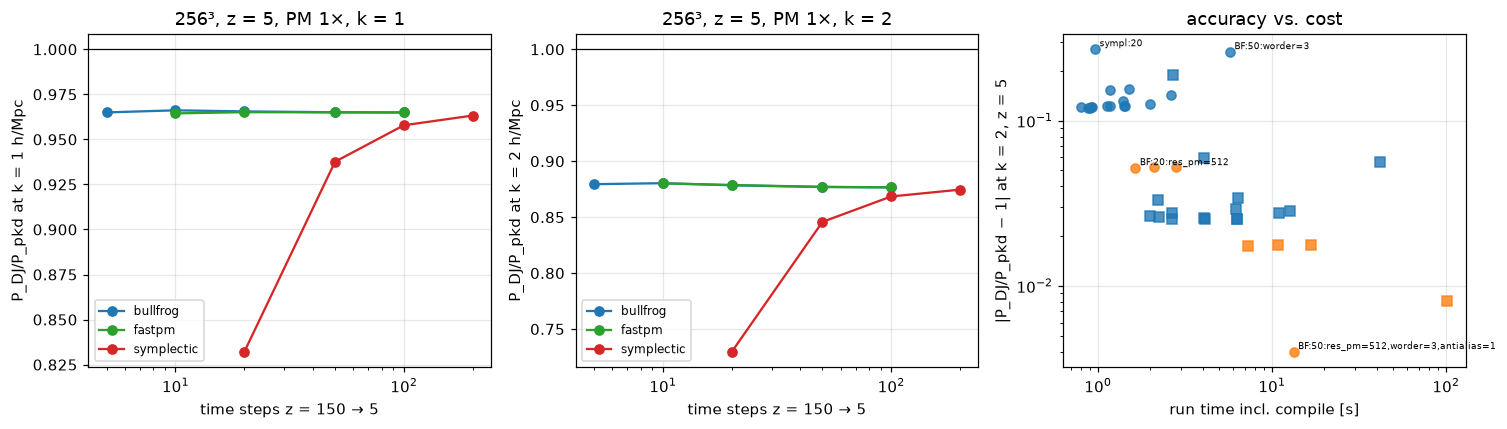

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
z5 = lambda r: next(o for o in r["outputs"] if o["z"] == 5.0)
d = byN[256]
for st, c in (("bullfrog", "C0"), ("fastpm", "C2"), ("symplectic", "C3")):
    rr = sorted([r for k_, r in d.items() if k_.split(":")[0] == st and len(k_.split(":")) == 2], key=lambda r: r["n_steps"])
    for j, k0 in enumerate((1.0, 2.0)):
        ax[j].semilogx([r["n_steps"] for r in rr], [at(z5(r), "ratio", k0) for r in rr], "o-", c=c, label=st)
for j, k0 in enumerate((1.0, 2.0)):
    ax[j].set(xlabel="time steps z = 150 → 5", ylabel=f"P_DJ/P_pkd at k = {k0:g} h/Mpc", title=f"256³, z = 5, PM 1×, k = {k0:g}")
    ax[j].axhline(1, c="k", lw=0.8); ax[j].legend(fontsize=8)
for N, mk in ((256, "o"), (512, "s")):
    for cfg, r in byN.get(N, {}).items():
        if r["status"] != "ok": continue
        o = z5(r); e = abs(at(o, "ratio", 2.0) - 1)
        ax[2].loglog(o["t_run_incl_compile"], e, mk, c="C1" if "res_pm" in cfg else "C0", alpha=0.8)
        if N == 256 and ("worder" in cfg or cfg in ("symplectic:20", "bullfrog:20:res_pm=512")):
            ax[2].annotate(cfg.replace("bullfrog", "BF").replace("symplectic", "sympl"), (o["t_run_incl_compile"], e),
                           fontsize=6, xytext=(3, 2), textcoords="offset points")
ax[2].set(xlabel="run time incl. compile [s]", ylabel="|P_DJ/P_pkd − 1| at k = 2, z = 5", title="accuracy vs. cost")
plt.tight_layout()

- BullFrog and FastPM converge after 5–10 steps from z = 150; more steps change P(k) by < 1 %. The symplectic leapfrog needs ≳ 100–200 steps.
- The PM grid sets the small-scale accuracy: PM 1× lacks ~12–15 % power at k = 2 at 256³ (~4 % at 512³, where k = 2 is further from the grid scale); PM 2× with CIC overshoots (+5 % at k = 2, 256³).
- PM 2× with TSC + interlacing is within 1 % to k = 2 at z = 5 (256³), partly by a cancellation of under- and overshooting: at z = 10 the same run is 2.4 % low at k = 2 and 9 % low at k = 4. At 512³ (with unified memory, B4) it is within 1 % to k = 2 at z = 10 and 5, at ~10× the cost of PM 2× with CIC.

## B3. Cost of the 99 outputs
Outputs every 10.86 Myr from z = 30 to 5 (99 outputs). `collect_all=True` (one call, all outputs kept) fails in 3D at `a687972` (broadcasting bug, `disco_dj.py:1158`) and would need ≈ 99 × N³ × 24 B anyway, so the outputs are produced by one `run_nbody` call per output interval (12 steps to z = 30, then 1 step per interval), gridding each output on the GPU (CIC, 256³ unless noted), copying it to the host and writing it (A4).

Without `--jit-segments` every call is traced and compiled again (the scale factors are new Python floats); with it, one interval is compiled once with traced scale factors. Compared with a single run to z = 5 (50 steps, final state only).

In [12]:
b3 = load("B3") + load("D")
fin = {}
for r in b3:
    if r["params"]["outputs"] == "final" and r["status"] == "ok":
        p = r["params"]; fin[(p["res"], p["res_pm"], p["worder"], p["antialias"], p["lpt_order"])] = r
print(f"{'run':28s} {'job':>8s} {'N':>4s} {'PM':>3s} {'jit':>4s} {'status':>6s} {'loop[s]':>8s} {'step':>7s} {'grid':>6s} {'host':>5s} "
      f"{'io':>5s} {'snap':>5s} {'s/out':>6s} {'final[s]':>8s} {'peak':>6s}")
for r in b3:
    p = r["params"]
    if p["outputs"] != "loop": continue
    t = r["timings"]; sp = t.get("first_split", {})
    key = (p["res"], p["res_pm"], p["worder"], p["antialias"], p["lpt_order"])
    fr = fin.get(key)
    nout = len(r.get("a_outputs", [])) or 99
    print(f"{r['label']:28s} {r['_job']:8d} {p['res']:4d} {p['res_pm'] // p['res']:2d}x {('yes' if p.get('jit_segments') else 'no'):>4s} "
          f"{r['status']:>6s} {f2(t.get('first'),1):>8s} {f2(sp.get('step'),1):>7s} {f2(sp.get('grid'),1):>6s} "
          f"{f2(sp.get('host'),1):>5s} {f2(sp.get('io', 0),1):>5s} {f2(sp.get('snap', 0),1):>5s} "
          f"{f2(t['first'] / nout if 'first' in t else float('nan')):>6s} "
          f"{f2(fr['timings']['run'] if fr else float('nan'),1):>8s} {peak(r):6.1f}")

run                               job    N  PM  jit status  loop[s]    step   grid  host    io  snap  s/out final[s]   peak
N256_pm1_grid256              5809173  256  1x   no     ok     80.8    66.6    3.2   0.6   6.5   0.0   0.82      1.1    3.6
N256_pm1_nowrite              5809173  256  1x   no     ok     74.7    66.9    3.3   0.7   0.0   0.0   0.75      1.1    3.5
N512_pm1_grid256              5809173  512  1x   no     ok    243.8   207.0   23.6   0.7   7.4   0.0   2.46      4.0   26.2
N512_pm1_grid512              5809173  512  1x   no     ok     58.7    41.3    5.3   1.0   2.9   0.0   2.94      4.0   26.5
N256_pm1_grid256_jit          5810705  256  1x  yes     ok     15.9     6.0    3.5   0.7   2.0   0.0   0.16      1.1    3.1
N256_pm1_spo2_jit             5810705  256  1x  yes     ok     14.4     6.5    3.6   0.7   0.0   0.0   0.15      1.1    3.1
N512_pm1_grid256_jit          5810705  512  1x  yes     ok     64.9    33.4   23.8   0.6   1.8   0.0   0.66      4.0   23.0
N768_pm1

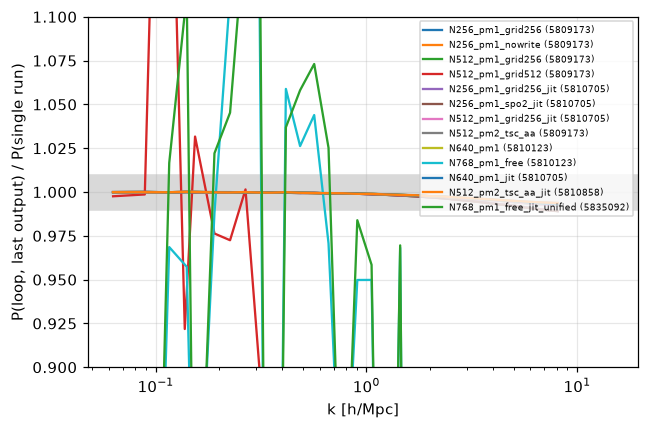

In [13]:
# Does stepping output by output change the result? P(k) of the last output (z = 5.015) vs. the run straight to
# z = 5, scaled by (a_5.015 / a_5)^2 for the growth over the 11 Myr difference (large-scale approximation).
fig, ax = plt.subplots(figsize=(6, 4))
for r in b3:
    p = r["params"]
    if p["outputs"] != "loop" or r["status"] != "ok" or "pk_outputs" not in r: continue
    fr = fin.get((p["res"], p["res_pm"], p["worder"], p["antialias"], p["lpt_order"]))
    zl = min(r["pk_outputs"], key=float)
    if not fr: continue
    kl, pl = kclean(r["pk_outputs"][zl], "pk"); kf, pf = kclean(fr["pk"], "pk")
    corr = ((1 + 5.0) / (1 + float(zl)))**2
    n = min(len(kl), len(kf))
    ax.semilogx(kl[:n], pl[:n] / pf[:n] / corr, label=f"{r['label']} ({r['_job']})")
ax.axhspan(0.99, 1.01, color="0.85"); ax.set(xlabel="k [h/Mpc]", ylabel="P(loop, last output) / P(single run)", ylim=(0.9, 1.1))
ax.legend(fontsize=6); plt.tight_layout()

- Without compiled segments the output loop is dominated by re-tracing/compiling every call (~0.7 s per output at 256³, ~2 s at 512³): 99 outputs at 512³ took 244 s against 4 s for a single run.
- With `--jit-segments` the stepping cost drops 3–11× (256³ PM 1×: 67 → 6 s; 512³ PM 1×: 207 → 33 s; 512³ PM 2× TSC + interlacing: 714 → 239 s). Then gridding the 99 outputs on 256³ is a large part of the rest (~0.24 s per output from 512³ particles); the host copy and writing (2 × 67 MB per output) cost < 0.1 s per output.
- Compiling the segment embeds DISCO-DJ's Lagrangian grid `q` (built with NumPy) as an XLA constant (N³ × 12 B: 1.6 GB at 512³, 5.4 GB at 768³), allocated outside JAX's pool. With `XLA_PYTHON_CLIENT_MEM_FRACTION=0.95` there is no room for it at 512³ PM 2× and 768³; 0.85 works for 512³. **At 768³ no setting works in HBM alone** (0.85/0.92: the run does not fit; 0.90/0.95: the constant does not); the uncompiled loop takes ≈ 12 min for 99 outputs. **With unified memory** (B4; job 5835092) the compiled loop runs at 768³: 5.9 min in total (time stepping 150 s instead of 610 s). Passing `q` as an argument instead of a constant would need a change in DISCO-DJ.

## B4. Memory limits
Attempts to go beyond 768³ on one GPU (50 steps, final state): 1LPT instead of 2LPT ICs, `chunk_size` (must divide N³), XLA allocator settings (`XLA_PYTHON_CLIENT_MEM_FRACTION=1.0`, `XLA_PYTHON_CLIENT_ALLOCATOR=platform`, which reports no peak), and N = 800–864. Labels `*_unified`: XLA's pool on CUDA managed memory (`TF_FORCE_UNIFIED_MEMORY=1`, `XLA_PYTHON_CLIENT_MEM_FRACTION=2.0`, i.e. up to 192 GB), so the GH200's LPDDR5X behind NVLink-C2C can back allocations beyond the 96 GB HBM.

In [14]:
print(f"{'label':28s} {'N':>5s} {'lpt':>3s} {'chunk':>9s} {'status':>6s} {'setup':>6s} {'run':>6s} {'peak':>6s}  failure")
for r in sorted(load("B4"), key=lambda r: (r["params"]["res"], r["label"])):
    p = r["params"]; t = r["timings"]
    err = r.get("error", "")
    m_ = re.search(r"allocate (\d+) bytes", err)
    where = "ICs" if "setup" not in t else ("time stepping" if "run" not in t else "")
    msg = (f"OOM in {where}" + (f", single allocation {int(m_.group(1)) / GiB:.1f} GiB" if m_ else "")) if r["status"] == "oom" else err[:70]
    print(f"{r['label']:28s} {p['res']:5d} {p['lpt_order']:3d} {str(p['chunk_size'] or '-'):>9s} {r['status']:>6s} "
          f"{f2(t.get('setup'),1):>6s} {f2(t.get('run'),1):>6s} {peak(r):6.1f}  {msg}")

label                            N lpt     chunk status  setup    run   peak  failure
N640_pm2_chunk                 640   2  16777216    oom   12.3      -   30.0  OOM in time stepping, single allocation 32.3 GiB
N640_pm2_unified               640   2         -     ok   20.1   23.1   70.5  
N768_chunk16777216             768   2  16777216     ok   22.9   18.2   67.5  
N768_chunk67108864             768   2  67108864  error   14.6      -   60.9  TypeError: cannot reshape array of shape (452984832, 1, 3) (size 13589
N768_lpt1                      768   1         -     ok   20.7   11.5   62.5  
N768_platform                  768   2         -     ok   18.0   20.1    0.0  
N768_pm2_lpt1_chunk            768   1  16777216    oom   12.3      -   33.8  OOM in time stepping, single allocation 55.7 GiB
N768_pm2_unified               768   2         -     ok   16.4  442.9  121.6  
N768_unified                   768   2         -     ok   24.4   18.0   67.5  
N800_lpt1                      800   

- **768³ is the limit in the GH200's 96 GB HBM**, with 2LPT or 1LPT ICs. From 800³ on, every variant runs out of memory: with 2LPT already while generating the ICs, with 1LPT in the time stepping.
- 1LPT ICs lower the peak at 768³ (62.5 vs. 67.5 GiB) and run faster (11.5 vs. 18 s); `chunk_size` does not lower the peak; the allocator settings do not change the limit.
- **Unified memory moves the limit** (jobs 5834328, 5835092): with the pool on CUDA managed memory, allocations beyond the 96 GB HBM spill into the GH200's LPDDR5X over NVLink-C2C.
  - Runs that only slightly exceed HBM stay fast: 896³ (peak 107 GiB) takes 40 s for 50 steps (≈ 1.4× the N³-scaled 768³ time); 640³ with PM 2× (70 GiB) 23 s; 768³ is as fast as in HBM alone (18 s).
  - Runs far beyond HBM slow down strongly: 768³ with PM 2× (peak 122 GiB) runs, but takes 234–443 s for 50 steps, ~5–9× the expected in-HBM time.
  - **1024³ does not fit** on one GPU even with the pool at 2.2 × HBM (≈ 211 GB, about HBM + host memory per GPU), with 1LPT or 2LPT ICs: a single 102 GiB allocation in the time stepping fails.
- Beyond that, runs need a distributed (multi-GPU) version of DISCO-DJ, which the public code does not have yet.

## B5. Tree-PM
**Not possible at this commit:** `run_nbody(method="treepm")` raises `NotImplementedError` at `a687972`; the C++ tree is only reachable through `evaluate_acceleration` (single force evaluation).

## B6. Gradients
Loss = mean(δ²) of the final CIC field as a function of the real-space white noise (2LPT ICs, BullFrog, PM 1×, z = 150 → 5). Reverse mode with DISCO-DJ's adjoint method vs. plain backprop through the trajectory; forward-mode `jax.jvp` is not supported (the force has a `custom_vjp`).

label                      status   run[s] compile[s] peak[GiB]
N64_s10_forward                ok    0.004        2.1      0.07
N64_s10_grad_adjoint           ok    0.011        4.3      0.26
N64_s10_grad_backprop          ok    0.009        4.4      0.26
N64_s10_jvp                 error        -          -      0.00  TypeError: can't apply forward-mode autodiff (jvp) to a cust
N128_s10_forward               ok    0.012        2.2      0.33
N128_s10_grad_adjoint          ok    0.047        6.5      1.12
N128_s10_grad_backprop         ok    0.040        6.3      1.49
N128_s10_jvp                error        -          -      0.02  TypeError: can't apply forward-mode autodiff (jvp) to a cust
N256_s10_forward               ok    0.081        4.9      2.66
N256_s10_grad_adjoint          ok    0.355        9.7      9.57
N256_s10_grad_backprop         ok    0.332        9.1     12.76
N256_s10_jvp                error        -          -      0.13  TypeError: can't apply forward-mode autodif

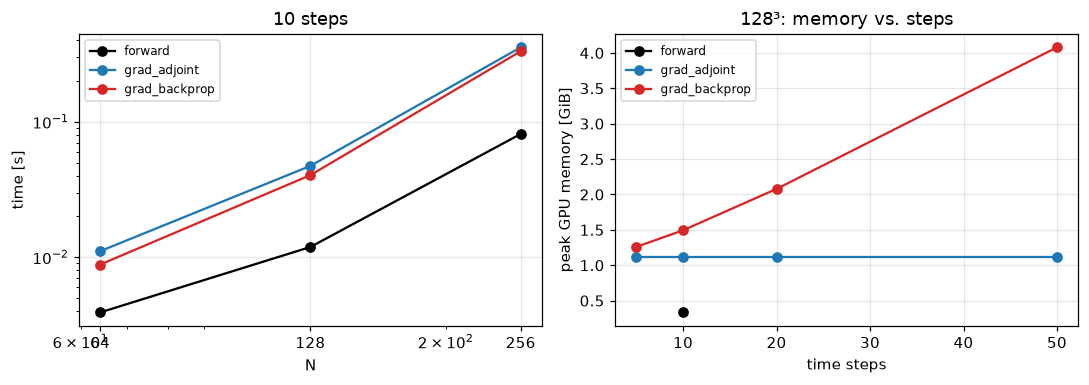

In [15]:
b6 = load("B6", latest=True)
print(f"{'label':26s} {'status':>6s} {'run[s]':>8s} {'compile[s]':>10s} {'peak[GiB]':>9s}")
for r in b6:
    print(f"{r['label']:26s} {r['status']:>6s} {f2(r['timings'].get('run'),3):>8s} {f2(r['timings'].get('compile'),1):>10s} {peak(r):9.2f}"
          + ("  " + r.get("error", "")[:60] if r["status"] != "ok" else ""))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for mode, c in (("forward", "k"), ("grad_adjoint", "C0"), ("grad_backprop", "C3")):
    rr = sorted([r for r in b6 if r["params"]["mode"] == mode and r["params"]["n_steps"] == 10 and r["status"] == "ok"],
                key=lambda r: r["params"]["res"])
    ax[0].loglog([r["params"]["res"] for r in rr], [r["timings"]["run"] for r in rr], "o-", c=c, label=mode)
    rr = sorted([r for r in b6 if r["params"]["mode"] == mode and r["params"]["res"] == 128 and r["status"] == "ok"],
                key=lambda r: r["params"]["n_steps"])
    ax[1].plot([r["params"]["n_steps"] for r in rr], [peak(r) for r in rr], "o-", c=c, label=mode)
ax[0].set(xlabel="N", ylabel="time [s]", title="10 steps"); ax[0].set_xticks([64, 128, 256], [64, 128, 256])
ax[1].set(xlabel="time steps", ylabel="peak GPU memory [GiB]", title="128³: memory vs. steps")
for a in ax: a.legend(fontsize=8)
plt.tight_layout()

A gradient costs ≈ 4× a forward evaluation; the adjoint method keeps the memory independent of the number of steps (1.1 GiB at 128³ for 5–50 steps), backprop grows with it (1.3 → 4.1 GiB).

# C. Throughput per node

## C1. 1, 2 and 4 runs per node
k = 1, 2, 4 independent runs at the same time on one node, one per GPU with its 72 Grace cores (50 steps, final state). Interference = time with k concurrent runs / time alone.

In [16]:
c_ = load("C")
cases = sorted({r["label"].split("_k")[0] for r in c_}, key=lambda s: int(s[1:].split("_")[0]))
print(f"{'case':10s} {'k':>2s} {'run[s]':>7s} {'setup[s]':>8s} {'run/run(k=1)':>12s} {'setup/setup(k=1)':>16s} {'runs/node-h':>11s}")
for cs in cases:
    base = None
    for k in (1, 2, 4):
        rr = [r for r in c_ if r["label"].startswith(f"{cs}_k{k}_") and r["status"] == "ok"]
        if not rr: continue
        run = np.mean([r["timings"]["run"] for r in rr]); setup = np.mean([r["timings"]["setup"] for r in rr])
        first = np.mean([r["timings"]["first"] for r in rr])
        if base is None: base = (run, setup)
        print(f"{cs:10s} {k:2d} {run:7.2f} {setup:8.2f} {run / base[0]:12.3f} {setup / base[1]:16.3f} {k * 3600 / (setup + first):11.0f}")

case        k  run[s] setup[s] run/run(k=1) setup/setup(k=1) runs/node-h
N256_pm2    1    1.96    14.82        1.000            1.000         195
N256_pm2    2    1.98    10.26        1.008            0.692         517
N256_pm2    4    1.95    12.61        0.992            0.851         890
N512_pm1    1    3.97     9.83        1.000            1.000         231
N512_pm1    2    4.06    11.52        1.022            1.171         417
N512_pm1    4    4.01    13.78        1.009            1.402         741
N768_pm1    1   17.99    14.48        1.000            1.000         105
N768_pm1    2   18.00    15.99        1.000            1.104         201
N768_pm1    4   17.88    18.00        0.994            1.243         383


No measurable interference in the time stepping (≤ 3 %); setup (on the CPU) grows by 24–40 % with 4 concurrent runs. A node therefore gives 4× the single-GPU throughput. Arrhenius bills whole nodes (a 1-GPU job is billed for 4 GPUs), so independent runs should be packed 4 per node.

## C2. Multi-GPU scaling of a single run
**Not possible:** the public DISCO-DJ runs on one device (no `jax.distributed`, sharding or MPI). To do if a distributed version becomes available.

# D. End-to-end run

## D1. Production-style runs
L = 100 Mpc/h to z = 5: all 99 outputs (z = 30 → 5) as 256³ density grids in pyC2Ray format, HDF5 particle snapshots (Gadget format, `save_as_hdf5`) at the listed redshifts. `--free-ics` drops the IC and nLPT fields after the first segment (needed for 768³). 768³ (PM 1×) is the largest that fits in HBM (B4) and uses the compiled output loop only with unified memory (B3).

## D2. Time split and output sizes
setup = timetables + linear P(k) + ICs + nLPT; loop = time stepping (step, incl. compilation), gridding (grid), grid writing (io), snapshots (snap). Total = setup + loop.

In [17]:
dd = [r for r in load("D") if r["params"]["outputs"] == "loop"]
print(f"{'run':28s} {'job':>8s} {'status':>6s} {'setup':>6s} {'loop':>7s} {'total':>7s} {'step':>6s} {'grid':>5s} {'io':>5s} {'snap':>5s} "
      f"{'grids [GB]':>10s} {'snaps [GB]':>10s} {'peak':>6s}")
for r in dd:
    t = r["timings"]; sp = t.get("first_split", {}); io = r.get("io", {})
    tot = t.get("setup", 0) + t.get("first", float("nan"))
    print(f"{r['label']:28s} {r['_job']:8d} {r['status']:>6s} {f2(t.get('setup'),0):>6s} {f2(t.get('first'),0):>7s} {f2(tot,0):>7s} "
          f"{f2(sp.get('step'),0):>6s} {f2(sp.get('grid'),0):>5s} {f2(sp.get('io', 0),0):>5s} {f2(sp.get('snap', 0),0):>5s} "
          f"{io.get('grid_bytes', 0) / 1e9:10.1f} {io.get('snap_bytes', 0) / 1e9:10.1f} {peak(r):6.1f}"
          + ("  " + r.get("error", "")[:50] if r["status"] != "ok" else ""))

run                               job status  setup    loop   total   step  grid    io  snap grids [GB] snaps [GB]   peak
N768_pm1                      5809173    oom     24       -       -      -     -     0     0        0.1        0.0   62.4  XlaRuntimeError: RESOURCE_EXHAUSTED: Out of memory
N512_pm2_tsc_aa               5809173     ok     19     785     804    714    25     7     8       13.3       17.2   55.1
N640_pm1                      5810123     ok     17     426     444    357    47     7     7       13.3       16.8   50.9
N768_pm1_free                 5810123     ok     20     715     735    610    82     7     5       13.3       14.5   76.0
N768_pm1_lpt1_free            5810123     ok     12     672     685    583    79     0     0        0.0        0.0   76.0
N512_pm2_tsc_aa_jit           5810705  error     19       -       -      -     -     0     0        0.1        0.0   52.0  XlaRuntimeError: INTERNAL: Failed to allocate 2151
N768_pm1_free_jit             5810705  err

# E. Post-processing for pyC2Ray
Not done in this round: it needs haloes, which DISCO-DJ does not provide, and is left for later.

## E1. Source model
**Not done.** Options: an external halo finder on the HDF5 particle snapshots of D, or a sub-grid source model on the density grids.

## E2. Conversion to pyC2Ray input
**Density part done, sources not done.** The density grids are written directly in pyC2Ray's format during the run (A4; cost in D2: < 0.1 s and 67 MB per output and format). The source lists depend on E1.

## E3. pyC2Ray run on the D output
**Not done:** depends on E1; to be compared with the same run on pkdgrav3 input (#47 E) and linked to #45 D.

# F. Resource estimates

## F1. GPU-hours and storage per run and per ensemble (N-body part)
From the D runs (best timing per configuration, compiled segments where available), packing 4 runs per node (C): GPU-hours per run = wall time; node-hours = GPU-hours / 4. Storage per run: 99 density grids (256³ float32, one format) plus particle snapshots (N³ × 24 B each) at the redshifts needed.

In [18]:
best = {}
for r in dd:
    if r["status"] != "ok": continue
    p = r["params"]; key = (p["res"], p["res_pm"] // p["res"], p["worder"], p["antialias"], p["lpt_order"])
    tot = r["timings"]["setup"] + r["timings"]["first"]
    if key not in best or tot < best[key][0]: best[key] = (tot, r)
grid_gb = 99 * 256**3 * 4 / 1e9
print(f"{'N':>4s} {'PM':>3s} {'MAK':>4s} {'AA':>3s} {'LPT':>3s} {'wall/run [min]':>14s} {'GPU-h/run':>9s} {'node-h/run':>10s} "
      f"{'grids [GB]':>10s} {'snapshot [GB]':>13s} {'100 runs: node-h':>16s}")
for (N, pm, w, aa, lpt), (tot, r) in sorted(best.items()):
    gh = tot / 3600
    print(f"{N:4d} {pm:2d}x {w:4d} {aa:3d} {lpt:3d} {tot / 60:14.1f} {gh:9.3f} {gh / 4:10.3f} {grid_gb:10.1f} "
          f"{N**3 * 24 / 1e9:13.1f} {100 * gh / 4:16.1f}")

   N  PM  MAK  AA LPT wall/run [min] GPU-h/run node-h/run grids [GB] snapshot [GB] 100 runs: node-h
 512  2x    2   0   2            1.8     0.030      0.007        6.6           3.2              0.7
 512  2x    3   1   2            5.5     0.091      0.023        6.6           3.2              2.3
 640  1x    2   0   2            2.3     0.039      0.010        6.6           6.3              1.0
 768  1x    2   0   1           11.4     0.190      0.048        6.6          10.9              4.8
 768  1x    2   0   2            5.9     0.098      0.025        6.6          10.9              2.5


These numbers are for the N-body part with 256³ output grids and no halo finding (E). For comparison with pkdgrav3 see `pkdgrav3_benchmarks_arrhenius.ipynb` (#47).

### Next to pkdgrav3 (#47)
Cost of one full run z = 150 → 5 with all outputs, from the D runs of both codes (pkdgrav3: `pkdgrav3/benchmark_results/arrhenius/D`, 1024³ on one node with 4 GH200, 110 steps, θ = 0.7, FoF and in-situ 256³/512³ grids at every step, serial snapshot/checkpoint writing). GPU-µs per particle = GPUs × wall / N³, a resolution-independent measure of the cost of one run.

In [19]:
pk = Path("pkdgrav3/benchmark_results/arrhenius/D")
pkd = [r for f in sorted(pk.glob("D_*.json")) for r in json.loads(f.read_text())["records"]
       if r["label"] == "N1024_prod" and r.get("finished")]
print(f"{'code':9s} {'run':32s} {'N':>5s} {'GPUs':>4s} {'wall [min]':>10s} {'GPU-h':>6s} {'GPU-h w/o I/O':>13s} {'GPU-us/particle':>15s}")
for r in pkd[-1:]:
    n = round(r["n_particles"] ** (1 / 3)); io = sum(r["timing"].get("IO", []))
    print(f"{'pkdgrav3':9s} {r['label']:32s} {n:5d} {4:4d} {r['wall_s'] / 60:10.1f} {4 * r['wall_s'] / 3600:6.2f} "
          f"{4 * (r['wall_s'] - io) / 3600:13.2f} {4 * r['wall_s'] / r['n_particles'] * 1e6:15.2f}")
for (N, pm, w, aa, lpt), (tot, r) in sorted(best.items()):
    sp = r["timings"].get("first_split", {}); io = sp.get("io", 0) + sp.get("snap", 0)
    print(f"{'DISCO-DJ':9s} {r['label']:32s} {N:5d} {1:4d} {tot / 60:10.1f} {tot / 3600:6.2f} {(tot - io) / 3600:13.2f} "
          f"{tot / N**3 * 1e6:15.2f}")

code      run                                  N GPUs wall [min]  GPU-h GPU-h w/o I/O GPU-us/particle
pkdgrav3  N1024_prod                        1024    4       64.2   4.28          3.13           14.34
DISCO-DJ  N512_pm2_jit                       512    1        1.8   0.03          0.03            0.80
DISCO-DJ  N512_pm2_tsc_aa_jit                512    1        5.5   0.09          0.09            2.44
DISCO-DJ  N640_pm1_jit                       640    1        2.3   0.04          0.04            0.53
DISCO-DJ  N768_pm1_lpt1_free                 768    1       11.4   0.19          0.19            1.51
DISCO-DJ  N768_pm1_free_jit_unified          768    1        5.9   0.10          0.09            0.78


- Per particle, a DISCO-DJ run with all outputs costs 0.5–2.4 GPU-µs against 14 GPU-µs for pkdgrav3 (10.5 without its serial I/O, which `bParaWrite` largely removes, #47 D3): **≈ 4–25× cheaper**, depending on the PM grid and assignment scheme.
- The comparison is not like-for-like: pkdgrav3 resolves small scales with the tree (DISCO-DJ's PM lacks power beyond k ≈ 1–2 h/Mpc at these resolutions unless the PM grid is refined, A3), runs FoF at every step (the haloes DISCO-DJ does not provide, E), and scales to many nodes (#47 C), while DISCO-DJ is limited to one GPU (768³ in HBM, 896³ with unified memory, B4).

## F2. Combined N-body + pyC2Ray estimate
**Not done:** needs E and the pyC2Ray numbers of #45; summary to #43 once available.

# Status and open items
DISCO-DJ is new (no release yet; `main` at `a687972`), so these benchmarks stop at what the current code supports. To revisit with a newer version:

| Item | Status at `a687972` | To do later |
|---|---|---|
| B3 `collect_all` | broken in 3D (broadcasting error in `run_nbody`) | compare with the per-output loop once fixed |
| B3/D compiled loop at 768³ | `q` grid as an XLA constant does not fit in HBM; works with unified memory | in HBM only if `q` becomes an argument |
| B4 largest run | 768³ in HBM, 896³ with unified memory; 1024³ does not fit | larger runs need a distributed version |
| B5 Tree-PM | `run_nbody(method="treepm")` not implemented | time and small-scale accuracy vs. PM |
| B6 forward mode | `jax.jvp` unsupported (`custom_vjp`) | only if needed |
| C multi-GPU | no distributed version | scaling of a single run |
| E halo/source model, pyC2Ray run | not started (needs haloes) | external halo finder or sub-grid sources |
| F2 with pyC2Ray | N-body part only (F1, incl. pkdgrav3 comparison) | combine with #45 |

Upstream issues found: the 3D `collect_all` bug; `evaluate_cross_power_spectrum` returns r(k) as its second value although the docstring says P_x; `chunk_size` must divide N³; the developers have not yet been asked about multi-GPU plans.